# Tutorial 5: The knowledge graph of a study

A study has a **topic**, the **PubMed searches** that collect its literature, and optionally **key articles** whose evidence neighborhood belongs in it. `create_kg` turns all of that into an [Obsidian](https://obsidian.md) vault, `kg_<topic>`, with one linked note per paper, MeSH concept and collection.

This tutorial builds such a graph for a real question, **how the gut microbiome relates to frailty and sarcopenia**, and then explains what it contains with charts:

| Question | Chart |
|---|---|
| What is in the graph? | Notes by type |
| Where did the papers come from, and do the searches overlap? | Papers by source |
| Which years does it cover? | Papers by year |
| What does it look like? | The network |
| What is it about? | Top MeSH concepts, as major topic or mention |
| Which topics travel together? | Concept co-occurrence |
| Which papers matter most inside the study? | Most cited in the graph, and bridge papers |
| Who publishes it, and what kind of evidence is it? | Journals, publication types and flags |

The notebook queries NCBI and takes about three minutes; setting `NCBI_API_KEY` makes it faster. It needs the tutorial extras: `pip install "pubmed-stream[tutorials]"`.

## 1. Setup

`tutorial_utils` sits next to this notebook. It moves into `tutorials/workspace/`, so downloads stay out of the repository, and gives every chart the same colours: **blue** for papers with full text, **grey** for stub papers, **aqua** for MeSH concepts and **orange** for collections.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import tutorial_utils as tu

tu.setup()
tu.style()

import pubmed_stream
from pubmed_stream import create_kg

print("pubmed-stream", pubmed_stream.__version__)

pubmed-stream 0.2.0


## 2. Build the study's knowledge graph

Two searches collect recent full-text papers, and one key article adds its neighborhood: papers PubMed rates as similar, papers citing it, and papers it cites. The seed is a 2019 review, *Gut Microbiota, Muscle Mass and Function in Aging: A Focus on Physical Frailty and Sarcopenia* (PMID 31319564). These are the same settings as `tutorials/kg_study.py`.

In [2]:
TOPIC = "gut microbiome frailty"

result = create_kg(
    TOPIC,
    queries=[
        '"gut microbiota"[Title] AND frailty[Title/Abstract]',
        '"gut microbiota"[Title] AND sarcopenia[Title/Abstract]',
    ],
    seeds=["31319564"],
    max_results=25,        # full-text articles per search
    max_per_relation=30,   # similar, citing and cited articles of the seed
)
print(result)


Found 25 PMC IDs for '"gut microbiota"[Title] AND frailty[Title/Abstract]' (total PubMed results: 66)
Output directory: publications\gut_microbiota_Title_AND_frailty_Title_Abstract



3 articles were not available in PMC full-text


Progress: 25/25 processed (OK:12 | FAIL:3 | SKIP:10)

Download Summary
Keyword:           "gut microbiota"[Title] AND frailty[Title/Abstract]
Total found:       66
Requested:         25
[OK] Successful:   12
[FAIL] Failed:     3
  - Unavailable:   3
  - Errors:        0
[SKIP] Skipped:    10
Duration:          6.0s
Output directory:  publications\gut_microbiota_Title_AND_frailty_Title_Abstract



Found 25 PMC IDs for '"gut microbiota"[Title] AND sarcopenia[Title/Abstract]' (total PubMed results: 80)
Output directory: publications\gut_microbiota_Title_AND_sarcopenia_Title_Abstract



3 articles were not available in PMC full-text


Progress: 25/25 processed (OK:22 | FAIL:3 | SKIP:0)

Download Summary
Keyword:           "gut microbiota"[Title] AND sarcopenia[Title/Abstract]
Total found:       80
Requested:         25
[OK] Successful:   22
[FAIL] Failed:     3
  - Unavailable:   3
  - Errors:        0
[SKIP] Skipped:    0
Duration:          9.0s
Output directory:  publications\gut_microbiota_Title_AND_sarcopenia_Title_Abstract



Knowledge graph: gut microbiome frailty
Folder:            workspace\kg_gut_microbiome_frailty
Study searches:    2 (2 run now, 34 new articles)
Study seeds:       1 (1 fetched now)
Obsidian vault
Vault:             workspace\kg_gut_microbiome_frailty
Sources:           3
Papers:            127 (42 full text, 85 stubs)
MeSH concepts:     309
Collections:       3
Notes:             440 created, 0 updated, 0 unchanged
PubMed records:    51 fetched
  - Without MeSH:  32 (offline, or not yet indexed in PubMed)


## 3. Load the graph into Python

`tu.read_kg` reads the notes back, properties and links, so everything below is drawn from exactly what Obsidian shows.

In [3]:
kg = tu.read_kg(result.kg_dir)
papers = kg["papers"]

df = pd.DataFrame([
    {
        "paper": key,
        "title": p["title"],
        "year": p["year"],
        "journal": p["journal"],
        "full_text": p["status"] == "full-text",
        "cites_in_graph": sum(t in papers for t in p["cites"]),
        "concepts": len(p["concepts"]),
        "review": "pubmed/review" in p["tags"],
        "retracted": p["retracted"],
        "nih_funded": "pubmed/nih-funded" in p["tags"],
    }
    for key, p in papers.items()
])
df.head()

,paper,title,year,journal,full_text,cites_in_graph,concepts,review,retracted,nih_funded
0,PMID23648049,Association of frailty with body composition a...,2013,Journal of renal nutrition : the official jour...,False,0,14,False,False,True
1,PMID26484770,Overlaps between Frailty and Sarcopenia Defini...,2015,Nestle Nutrition Institute workshop series,False,0,16,True,False,False
2,PMID28894183,Gut microbiota composition is associated with ...,2017,Scientific reports,False,0,13,False,False,False
3,PMID29058056,Gut Microbiota Contribute to Age-Related Chang...,2018,Calcified tissue international,False,0,6,True,False,True
4,PMID29189738,Aging Gut Microbiota at the Cross-Road between...,2017,Nutrients,False,0,6,True,False,False


## 4. What is in the graph?

Every paper, MeSH heading and collection is a note. *Stub* papers are neighbors of the seed that were not downloaded; their notes hold PubMed details and links but no abstract.

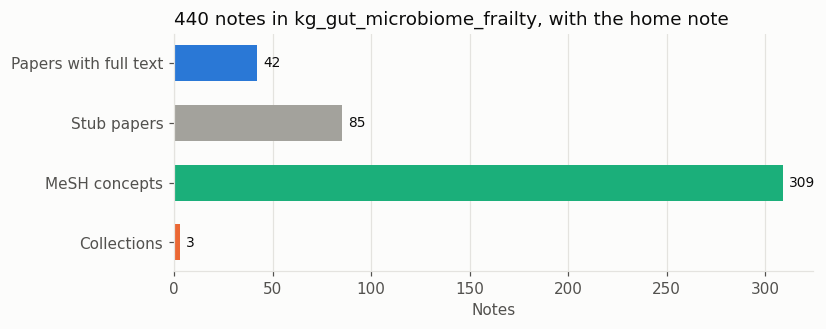

In [4]:
counts = {
    "Papers with full text": int(df.full_text.sum()),
    "Stub papers": int((~df.full_text).sum()),
    "MeSH concepts": len(kg["concepts"]),
    "Collections": len(kg["collections"]),
}
colours = [tu.BLUE, tu.GREY, tu.AQUA, tu.ORANGE]

fig, ax = plt.subplots(figsize=(7.5, 2.8))
bars = ax.barh(list(counts)[::-1], list(counts.values())[::-1], color=colours[::-1], height=0.6)
tu.bar_labels(ax, bars, horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Notes")
ax.set_title(f"{sum(counts.values()) + 1} notes in kg_gut_microbiome_frailty, with the home note")
plt.show()

## 5. Where did the papers come from?

Each paper belongs to one or more **collections**: a search or the seed's neighborhood. A paper in two collections is where the searches and the neighborhood meet. Those overlaps are the first sign the study hangs together.

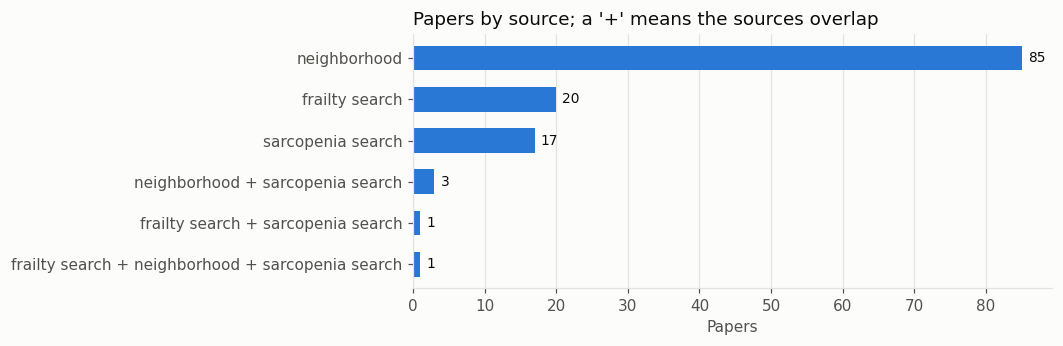

In [5]:
def source_label(paper):
    names = sorted(
        "frailty search" if "frailty" in c else "sarcopenia search" if "sarcopenia" in c else "neighborhood"
        for c in paper["collections"]
    )
    return " + ".join(names) or "none"

sources = Counter(source_label(p) for p in papers.values())
order = sorted(sources, key=lambda s: (s.count("+"), -sources[s]))

fig, ax = plt.subplots(figsize=(7.5, 3))
bars = ax.barh(order[::-1], [sources[s] for s in order][::-1], color=tu.BLUE, height=0.6)
tu.bar_labels(ax, bars, horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Papers")
ax.set_title("Papers by source; a '+' means the sources overlap")
plt.show()

## 6. Which years does it cover?

PMC returns the newest matches first, so the searches bring recent papers. The neighborhood reaches back: the seed's references, and the papers PubMed rates as similar, fill in the older literature.

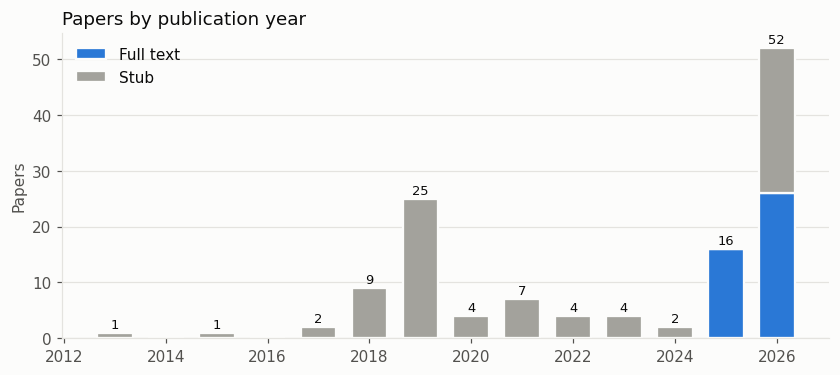

In [6]:
by_year = df.dropna(subset=["year"]).groupby(["year", "full_text"]).size().unstack(fill_value=0)
by_year = by_year.reindex(range(int(df.year.min()), int(df.year.max()) + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.6))
full = by_year.get(True, 0)
stub = by_year.get(False, 0)
ax.bar(by_year.index, full, width=0.7, color=tu.BLUE, edgecolor=tu.SURFACE, lw=1.5, label="Full text")
ax.bar(by_year.index, stub, width=0.7, bottom=full, color=tu.GREY, edgecolor=tu.SURFACE, lw=1.5, label="Stub")
for year, total in (full + stub).items():
    if total:
        ax.annotate(str(total), (year, total), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
tu.gridlines(ax)
ax.set_ylabel("Papers")
ax.legend(loc="upper left")
ax.set_title("Papers by publication year")
plt.show()

## 7. What does it look like?

The same structure Obsidian's graph view shows. Collections and the most connected MeSH concepts sit on the outer ring; papers sit inside, pulled toward what they cite, resemble and are about. Dark lines are citation and similarity links between papers.

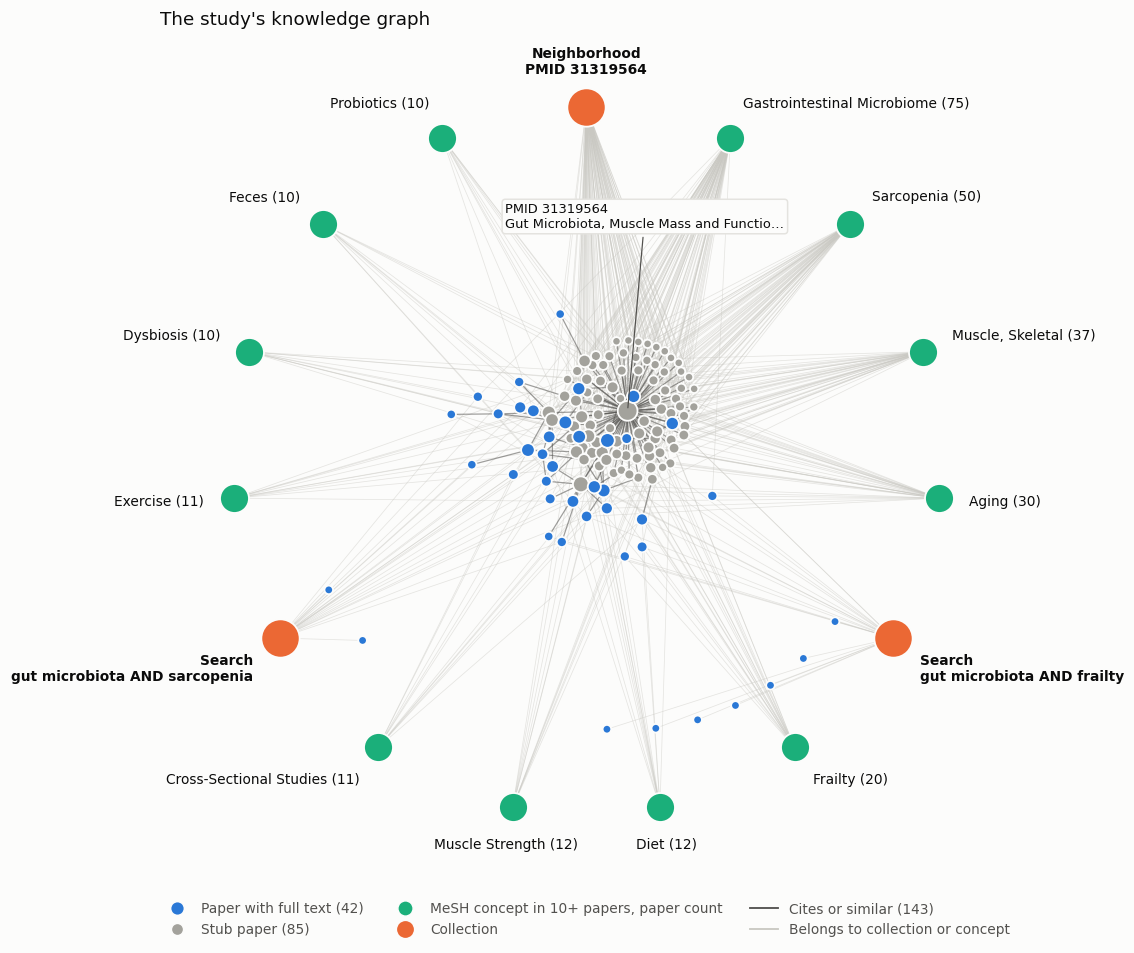

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
graph = tu.draw_network(kg, ax, min_concept_papers=10)
ax.set_title("The study's knowledge graph")
plt.show()

## 8. What is the study about?

MeSH indexers mark a heading as a **major topic** when it is a main point of the article, and as a plain heading when it is only discussed. The split tells a paper's subject from its setting. *Gastrointestinal Microbiome* is almost always a major topic here, while study-design and sample headings such as *Cross-Sectional Studies* or *Feces* are only ever mentioned.

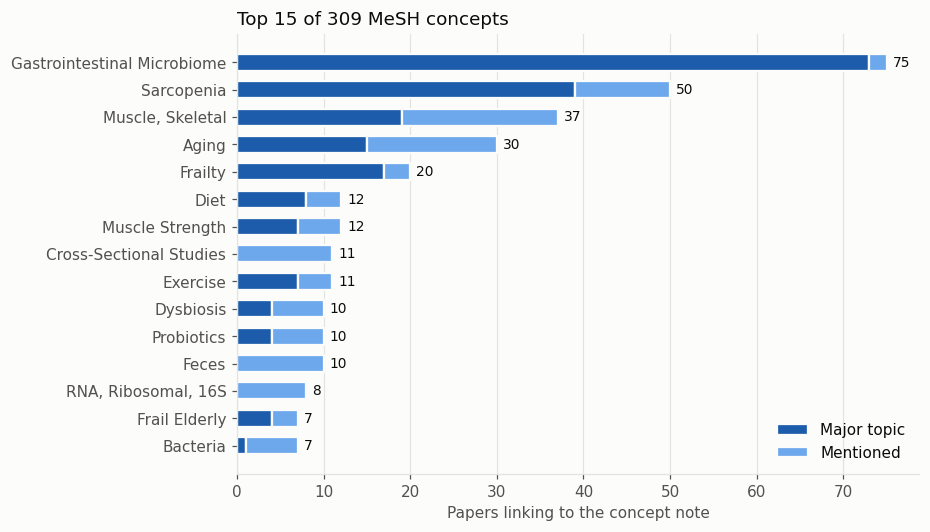

In [8]:
concept_rows = sorted(
    ((name, sum(members.values()), len(members) - sum(members.values())) for name, members in kg["concepts"].items()),
    key=lambda row: -(row[1] + row[2]),
)[:15][::-1]
names = [r[0] for r in concept_rows]
major = [r[1] for r in concept_rows]
minor = [r[2] for r in concept_rows]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(names, major, color=tu.BLUES[5], height=0.62, edgecolor=tu.SURFACE, lw=1.5, label="Major topic")
bars = ax.barh(names, minor, left=major, color=tu.BLUES[2], height=0.62, edgecolor=tu.SURFACE, lw=1.5, label="Mentioned")
for bar, a, b in zip(bars, major, minor):
    ax.annotate(str(a + b), (a + b, bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9)
tu.gridlines(ax, "x")
ax.set_xlabel("Papers linking to the concept note")
ax.legend(loc="lower right")
ax.set_title(f"Top 15 of {len(kg['concepts'])} MeSH concepts")
plt.show()

## 9. Which topics travel together?

Each cell counts the papers indexed with both concepts. Strong pairs show the study's core, here microbiome with sarcopenia and skeletal muscle. Weak or empty cells show topics the study touches separately.

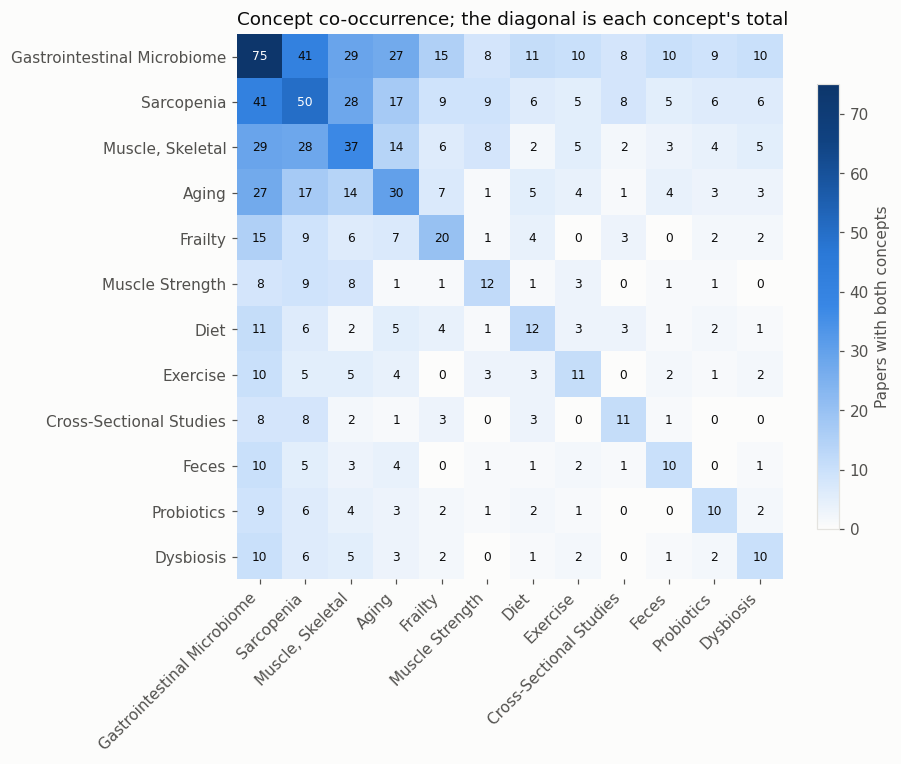

In [9]:
top = [name for name, _, _ in sorted(concept_rows, key=lambda r: -(r[1] + r[2]))[:12]]
matrix = pd.DataFrame(0, index=top, columns=top)
for p in papers.values():
    present = [c for c in top if c in p["concepts"]]
    for a in present:
        for b in present:
            matrix.loc[a, b] += 1

fig, ax = plt.subplots(figsize=(8, 7))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", [tu.SURFACE] + tu.BLUES)
im = ax.imshow(matrix.values, cmap=cmap)
ax.set_xticks(range(len(top)), top, rotation=45, ha="right")
ax.set_yticks(range(len(top)), top)
ax.spines[:].set_visible(False)
for i in range(len(top)):
    for j in range(len(top)):
        value = matrix.iat[i, j]
        ax.text(j, i, value, ha="center", va="center", fontsize=8,
                color="white" if value > matrix.values.max() * 0.55 else tu.INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Papers with both concepts")
ax.set_title("Concept co-occurrence; the diagonal is each concept's total")
plt.show()

## 10. Which papers matter most inside the study?

Counting citations **inside the graph** ranks papers by how much the study's own literature relies on them, which is a more focused signal than global citation counts. Stubs often rank high: they are the older, well-cited work the recent papers build on.

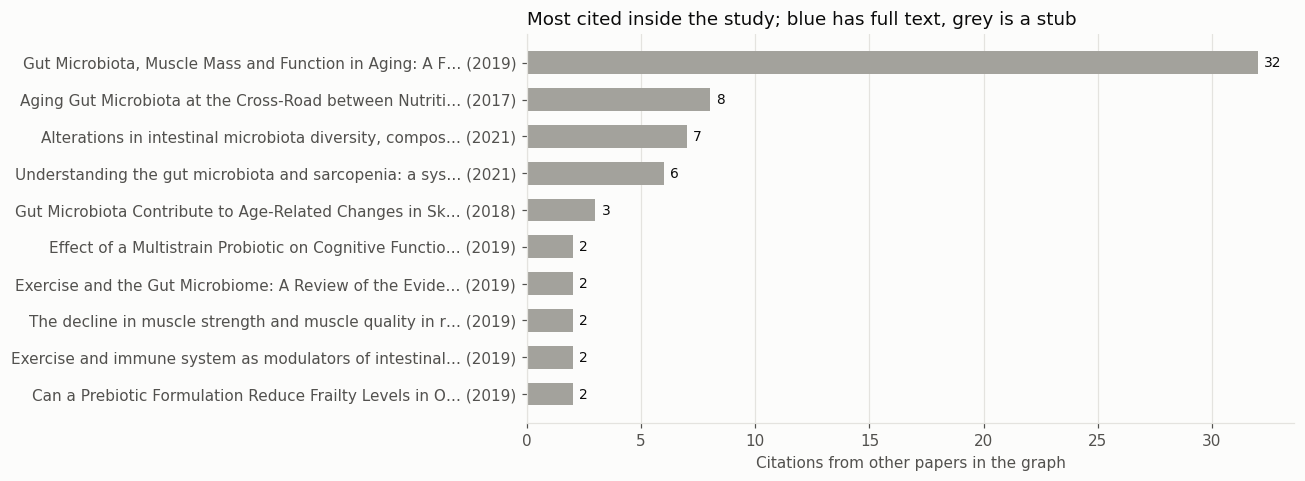

In [10]:
cited = Counter(t for p in papers.values() for t in p["cites"] if t in papers)
rows = cited.most_common(10)[::-1]
labels = [f"{tu.short(papers[k]['title'], 55)} ({papers[k]['year']})" for k, _ in rows]

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(labels, [n for _, n in rows], height=0.62,
               color=[tu.BLUE if papers[k]["status"] == "full-text" else tu.GREY for k, _ in rows])
tu.bar_labels(ax, bars, horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Citations from other papers in the graph")
ax.set_title("Most cited inside the study; blue has full text, grey is a stub")
plt.show()

**Bridge papers** connect parts of the graph that would otherwise be far apart. Betweenness centrality over the citation and similarity links finds them; they are good candidates to read first, because they link the searches to each other and to the older literature.

In [11]:
links = nx.Graph()
links.add_edges_from((k, t) for k, p in papers.items() for t in list(p["cites"]) + list(p["similar"]) if t in papers and t != k)
centrality = nx.betweenness_centrality(links)
bridges = sorted(centrality, key=centrality.get, reverse=True)[:8]
pd.DataFrame([
    {
        "paper": k,
        "year": papers[k]["year"],
        "title": tu.short(papers[k]["title"], 70),
        "status": papers[k]["status"],
        "sources": source_label(papers[k]),
        "betweenness": round(centrality[k], 3),
    }
    for k in bridges
])

,paper,year,title,status,sources,betweenness
0,PMID31319564,2019,"Gut Microbiota, Muscle Mass and Function in Ag...",stub,neighborhood,0.959
1,PMID29189738,2017,Aging Gut Microbiota at the Cross-Road between...,stub,neighborhood,0.103
2,PMID33633246,2021,Alterations in intestinal microbiota diversity...,stub,neighborhood,0.072
3,PMID34523250,2021,Understanding the gut microbiota and sarcopeni...,stub,neighborhood,0.055
4,PMID41601864,2026,Correlation between the gut microbiota composi...,full-text,frailty search,0.019
5,PMID40973020,2025,Gut Microbiota and Nutrition in Nursing Homes:...,full-text,frailty search,0.018
6,PMID42060019,2026,Association between gut microbiota and sarcope...,full-text,sarcopenia search,0.018
7,PMID35278043,2022,Gut microbes and muscle function: can probioti...,stub,neighborhood,0.018


## 11. Who publishes it, and what kind of evidence is it?

Journals show where the field publishes. Publication types and flags show the mix of evidence: how much is primary research, how much is review, and whether anything was retracted.

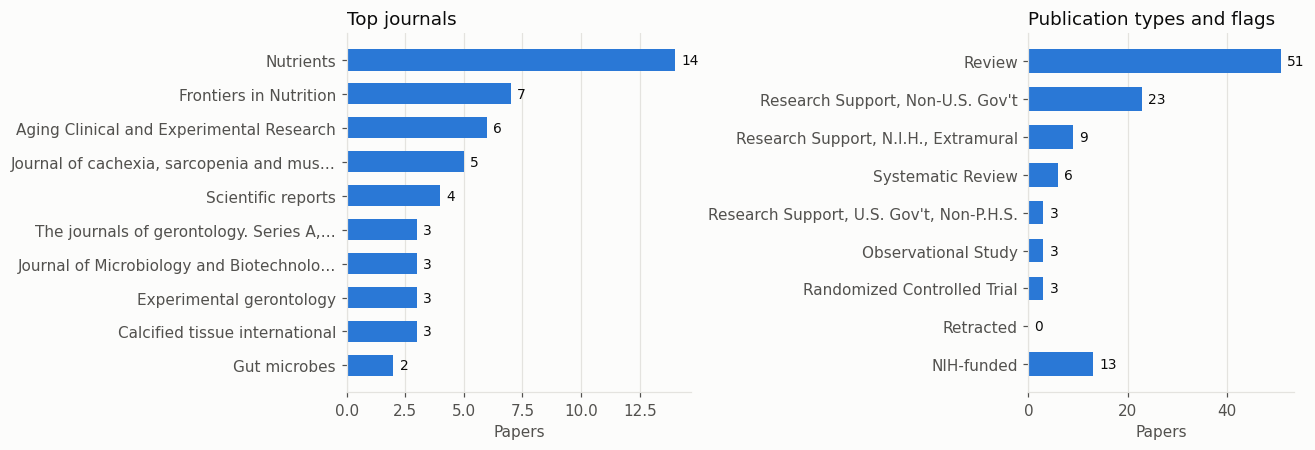

Reviews: 57 of 127 papers; retracted: 0


In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

# PMC and PubMed capitalise some journal names differently: count them as one
journal_names = df.journal.dropna()
spelling = journal_names.groupby(journal_names.str.casefold()).agg(lambda s: s.value_counts().index[0])
journals = journal_names.str.casefold().map(spelling).value_counts().head(10)[::-1]
bars = left.barh([tu.short(j, 40) for j in journals.index], journals.values, color=tu.BLUE, height=0.62)
tu.bar_labels(left, bars, horizontal=True)
tu.gridlines(left, "x")
left.set_xlabel("Papers")
left.set_title("Top journals")

types = Counter(t for p in papers.values() for t in p["publication_types"]
                if t not in ("Journal Article", "English Abstract"))
types = dict(types.most_common(7))
flags = {
    "Retracted": int(df.retracted.sum()),
    "NIH-funded": int(df.nih_funded.sum()),
}
evidence = {**types, **flags}
bars = right.barh(list(evidence)[::-1], list(evidence.values())[::-1], color=tu.BLUE, height=0.62)
tu.bar_labels(right, bars, horizontal=True, zero=True)
tu.gridlines(right, "x")
right.set_xlabel("Papers")
right.set_title("Publication types and flags")
plt.tight_layout()
plt.show()
print(f"Reviews: {int(df.review.sum())} of {len(df)} papers; retracted: {int(df.retracted.sum())}")

## 12. Read one paper's note

Every chart above comes from notes like this one: properties at the top, then a generated block with the abstract, MeSH concepts and links. Here is the most cited paper inside the study, shortened.

In [13]:
def show_note(path, properties=8, body_lines=28, width=150):
    _, frontmatter, body = path.read_text(encoding="utf-8").split("---", 2)
    props = frontmatter.strip().splitlines()
    lines = ["---"] + props[:properties] + (["..."] if len(props) > properties else []) + ["---"]
    body = [l if len(l) <= width else l[:width] + " ..." for l in body.strip("\n").splitlines()]
    print("\n".join(lines + body[:body_lines] + (["..."] if len(body) > body_lines else [])))

most_cited = cited.most_common(1)[0][0]
show_note(result.kg_dir / "papers" / f"{most_cited}.md")

---
type: "paper"
title: "Gut Microbiota, Muscle Mass and Function in Aging: A Focus on Physical Frailty and Sarcopenia."
aliases:
  - "Gut Microbiota, Muscle Mass and Function in Aging: A Focus on Physical Frailty and Sarcopenia."
pmid: "31319564"
pmcid: "PMC6683074"
doi: "10.3390/nu11071633"
year: 2019
...
---
%% pubmed-stream:start - generated; edits inside this block are overwritten %%
# Gut Microbiota, Muscle Mass and Function in Aging: A Focus on Physical Frailty and Sarcopenia.

> [!note] Stub
> Known from an evidence neighborhood; its full text has not been downloaded.

**Authors:** Ticinesi Andrea, Nouvenne Antonio, Cerundolo Nicoletta, Catania Pamela, Prati Beatrice, Tana Claudio, Meschi Tiziana
**Published:** *Nutrients* · 2019 · [PubMed](https://pubmed.ncbi.nlm.nih.gov/31319564/) · [PMC](https://pmc.ncbi.nlm.nih.gov/articles/PMC6683074/) · [ ...
**Publication type:** Journal Article, Review
**Collections:** [[Neighborhood - PMID 31319564]]

## MeSH concepts

- [[Frailty]] (

## 13. Keep working with it

- **Write in the notes.** Text outside the `%% pubmed-stream %%` block, and properties or tags you add in Obsidian, survive every rebuild.
- **Grow the study.** `create_kg(TOPIC, queries=[...])` with the same topic adds to this graph.
- **Keep it current.** `create_kg(TOPIC, refresh=True)` runs every search and seed again and adds newly published papers.
- **Explore it in Obsidian.** Open `tutorials/workspace/kg_gut_microbiome_frailty` with **Open folder as vault**, start at the `PubMed Stream` note, and open the graph view. The colours match these charts.

The same study from the command line:

```bash
pubmed-stream kg "gut microbiome frailty" \
    -q '"gut microbiota"[Title] AND frailty[Title/Abstract]' \
    -q '"gut microbiota"[Title] AND sarcopenia[Title/Abstract]' \
    --seed 31319564 --max-results 25 --max-per-relation 30
pubmed-stream kg "gut microbiome frailty" --refresh
```

In [14]:
from pubmed_stream import load_study

print(load_study(result.kg_dir))

{'topic': 'gut microbiome frailty', 'queries': ['"gut microbiota"[Title] AND frailty[Title/Abstract]', '"gut microbiota"[Title] AND sarcopenia[Title/Abstract]'], 'seeds': ['31319564']}
